In [1]:
import pandas as pd
from pathlib import Path

RESULTS_DIR = Path("results/scenario4_train_test_e4000")
df = pd.read_csv(RESULTS_DIR / "metrics.csv")

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Shape: (448, 8)
Columns: ['Model', 'PatchLen', 'Horizon', 'd_model', 'Set', 'Epochs', 'MSE', 'MAE']


,Model,PatchLen,Horizon,d_model,Set,Epochs,MSE,MAE
0,LSTM,40,2,48,Train,4000,0.006871,0.062362
1,LSTM,40,2,48,Test,4000,0.021254,0.109713
2,PatchTST,40,2,48,Train,4000,0.002933,0.041327
3,PatchTST,40,2,48,Test,4000,0.016703,0.095375
4,Autoformer,40,2,48,Train,4000,0.011293,0.080794


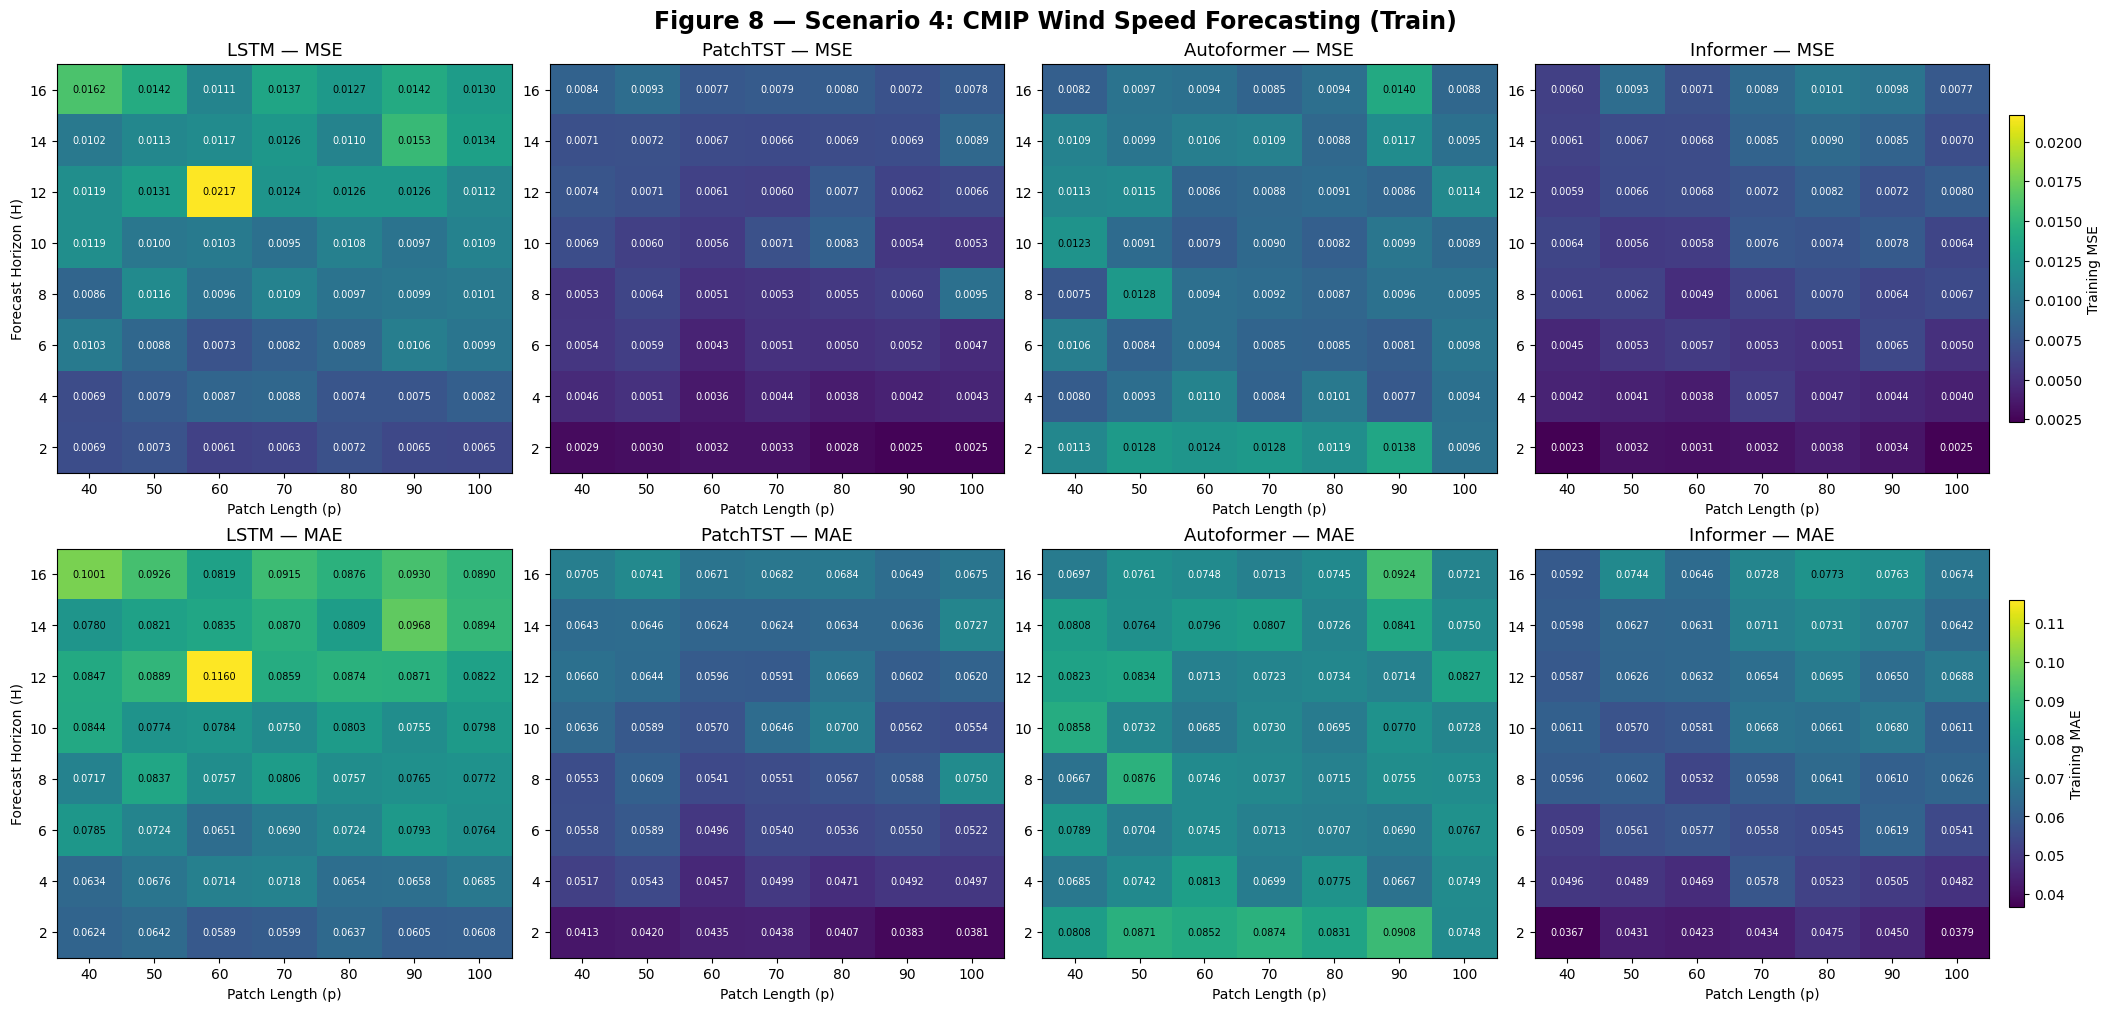

Saved: results\scenario4_train_test_e4000\figure8_train_heatmaps.png


In [2]:
import numpy as np
import matplotlib.pyplot as plt

train_df = df[df["Set"] == "Train"].copy()

models = ["LSTM", "PatchTST", "Autoformer", "Informer"]
metrics = ["MSE", "MAE"]
patch_lengths = sorted(df["PatchLen"].unique())
horizons = sorted(df["Horizon"].unique())

fig, axes = plt.subplots(2, 4, figsize=(21, 10), constrained_layout=True)

for row, metric in enumerate(metrics):
    # Dùng cùng thang màu cho các mô hình trong một hàng
    vmin = train_df[metric].min()
    vmax = train_df[metric].max()

    for col, model in enumerate(models):
        ax = axes[row, col]

        subset = train_df[train_df["Model"] == model]

        pivot = subset.pivot(
            index="Horizon",
            columns="PatchLen",
            values=metric
        ).reindex(index=horizons, columns=patch_lengths)

        values = pivot.to_numpy()

        im = ax.imshow(
            values,
            cmap="viridis",
            aspect="auto",
            origin="lower",
            vmin=vmin,
            vmax=vmax
        )

        ax.set_title(f"{model} — {metric}", fontsize=13)
        ax.set_xticks(range(len(patch_lengths)), patch_lengths)
        ax.set_yticks(range(len(horizons)), horizons)

        ax.set_xlabel("Patch Length (p)")
        if col == 0:
            ax.set_ylabel("Forecast Horizon (H)")

        for i in range(len(horizons)):
            for j in range(len(patch_lengths)):
                value = values[i, j]
                if not np.isnan(value):
                    ax.text(
                        j, i, f"{value:.4f}",
                        ha="center",
                        va="center",
                        fontsize=7,
                        color="white" if value < (vmin + vmax) / 2 else "black"
                    )

    fig.colorbar(
        im,
        ax=axes[row, :],
        shrink=0.75,
        pad=0.01,
        label=f"Training {metric}"
    )

fig.suptitle(
    "Figure 8 — Scenario 4: CMIP Wind Speed Forecasting (Train)",
    fontsize=17,
    fontweight="bold"
)

output_path = RESULTS_DIR / "figure8_train_heatmaps.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {output_path}")

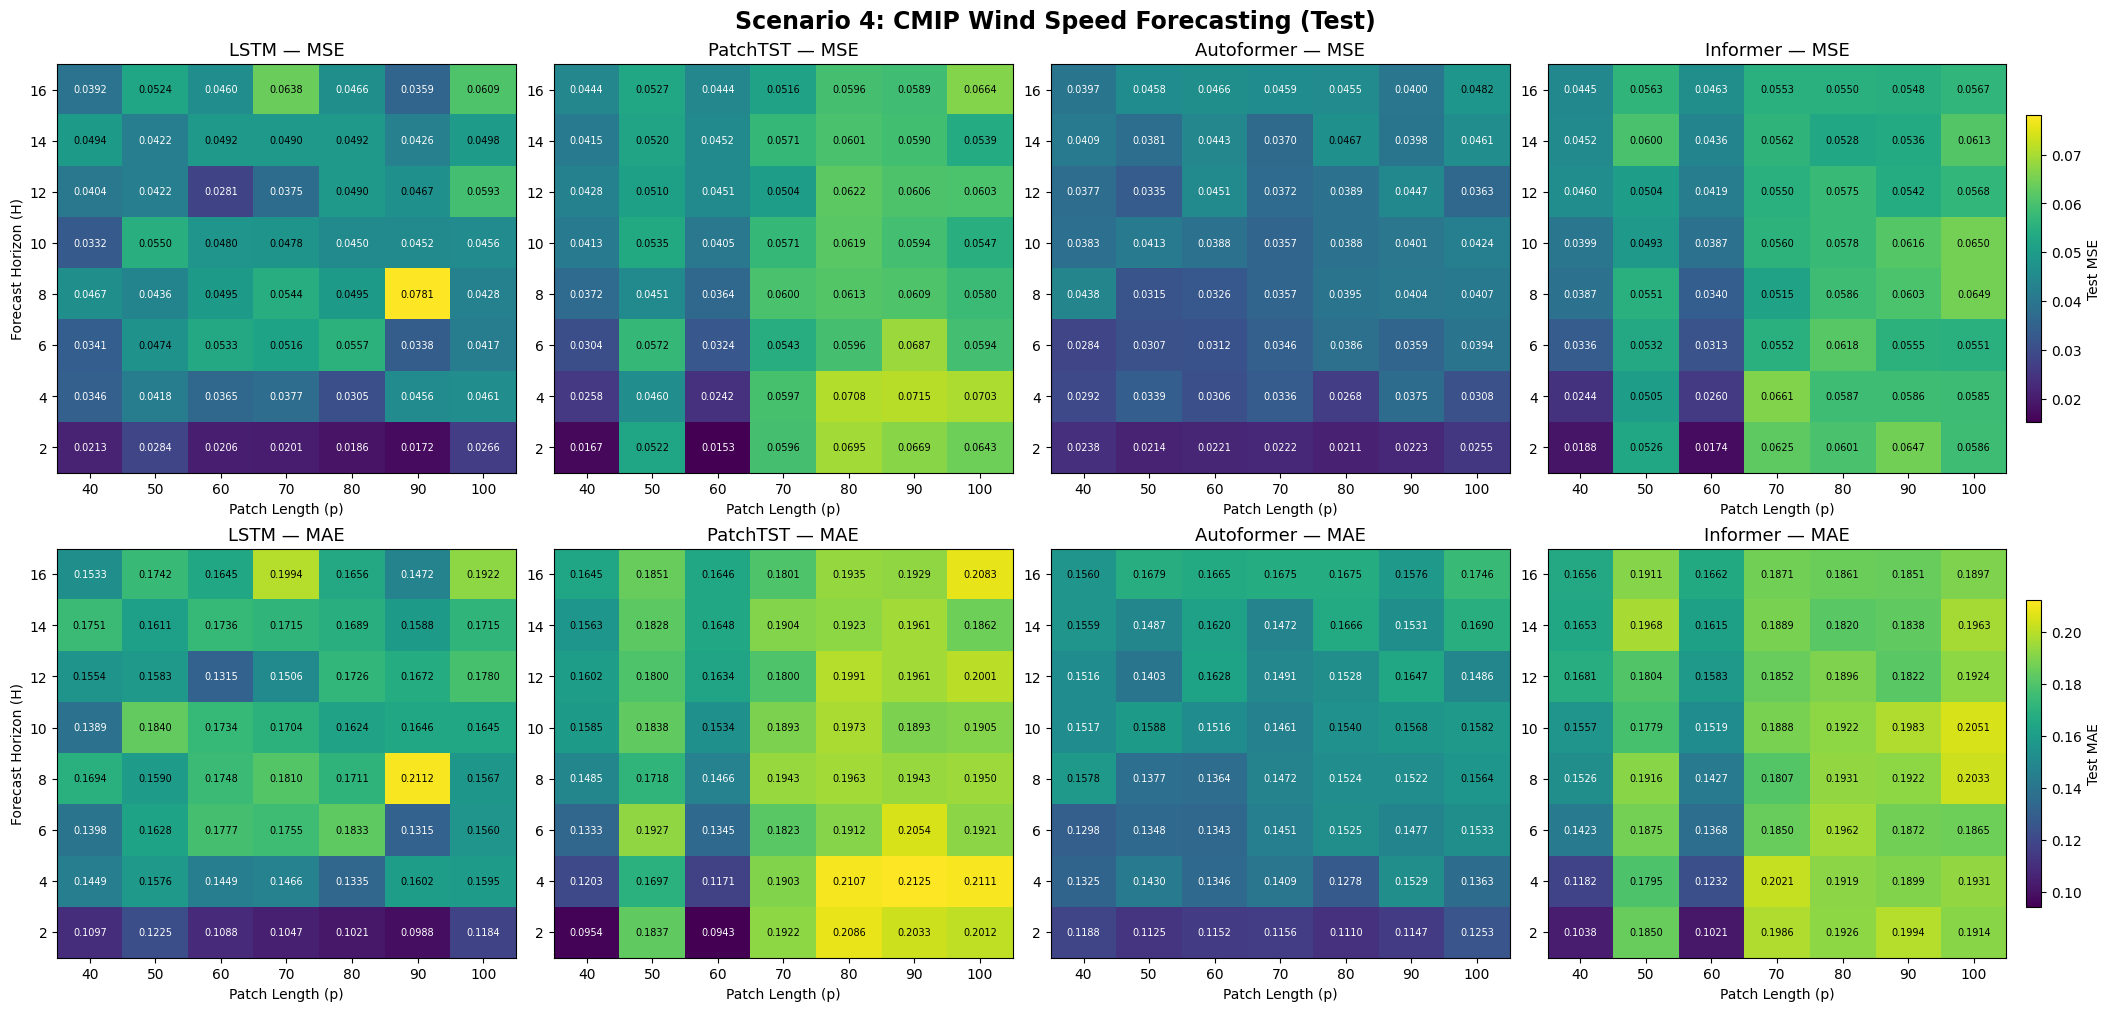

Saved: results\scenario4_train_test_e4000\figure9_test_heatmaps.png


In [3]:
test_df = df[df["Set"] == "Test"].copy()

fig, axes = plt.subplots(
    2, 4, figsize=(21, 10), constrained_layout=True
)

for row, metric in enumerate(metrics):
    vmin = test_df[metric].min()
    vmax = test_df[metric].max()

    for col, model in enumerate(models):
        ax = axes[row, col]

        subset = test_df[test_df["Model"] == model]

        pivot = subset.pivot(
            index="Horizon",
            columns="PatchLen",
            values=metric
        ).reindex(index=horizons, columns=patch_lengths)

        values = pivot.to_numpy()

        im = ax.imshow(
            values,
            cmap="viridis",
            aspect="auto",
            origin="lower",
            vmin=vmin,
            vmax=vmax
        )

        ax.set_title(f"{model} — {metric}", fontsize=13)
        ax.set_xticks(range(len(patch_lengths)), patch_lengths)
        ax.set_yticks(range(len(horizons)), horizons)

        ax.set_xlabel("Patch Length (p)")
        if col == 0:
            ax.set_ylabel("Forecast Horizon (H)")

        for i in range(len(horizons)):
            for j in range(len(patch_lengths)):
                value = values[i, j]
                if not np.isnan(value):
                    ax.text(
                        j, i, f"{value:.4f}",
                        ha="center",
                        va="center",
                        fontsize=7,
                        color="white" if value < (vmin + vmax) / 2 else "black"
                    )

    fig.colorbar(
        im,
        ax=axes[row, :],
        shrink=0.75,
        pad=0.01,
        label=f"Test {metric}"
    )

fig.suptitle(
    "Scenario 4: CMIP Wind Speed Forecasting (Test)",
    fontsize=17,
    fontweight="bold"
)

output_path = RESULTS_DIR / "figure9_test_heatmaps.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {output_path}")

In [4]:
import torch

checkpoint_path = RESULTS_DIR / "patchtst_p40_h8_d48.pt"

ckpt = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

for key, value in ckpt.items():
    if isinstance(value, torch.Tensor):
        print(f"{key}: Tensor {tuple(value.shape)}")
    elif isinstance(value, np.ndarray):
        print(f"{key}: ndarray {value.shape}")
    else:
        print(f"{key}: {type(value).__name__}")

model: str
model_state_dict: dict
pred_train: Tensor (2208, 40)
truth_train: Tensor (2208, 40)
pred_test: Tensor (456, 40)
truth_test: Tensor (456, 40)
loss: Tensor (4000,)
eig: Tensor (4000,)
train_mse: float
train_mae: float
test_mse: float
test_mae: float
patch_len: int
horizon: int
seq_len: int
d_model: int
input_dim: int
epochs: int
data_hash: str
rng_torch: Tensor (5056,)
rng_cuda: list


Figure 10 — Test predictions at five spatial locations

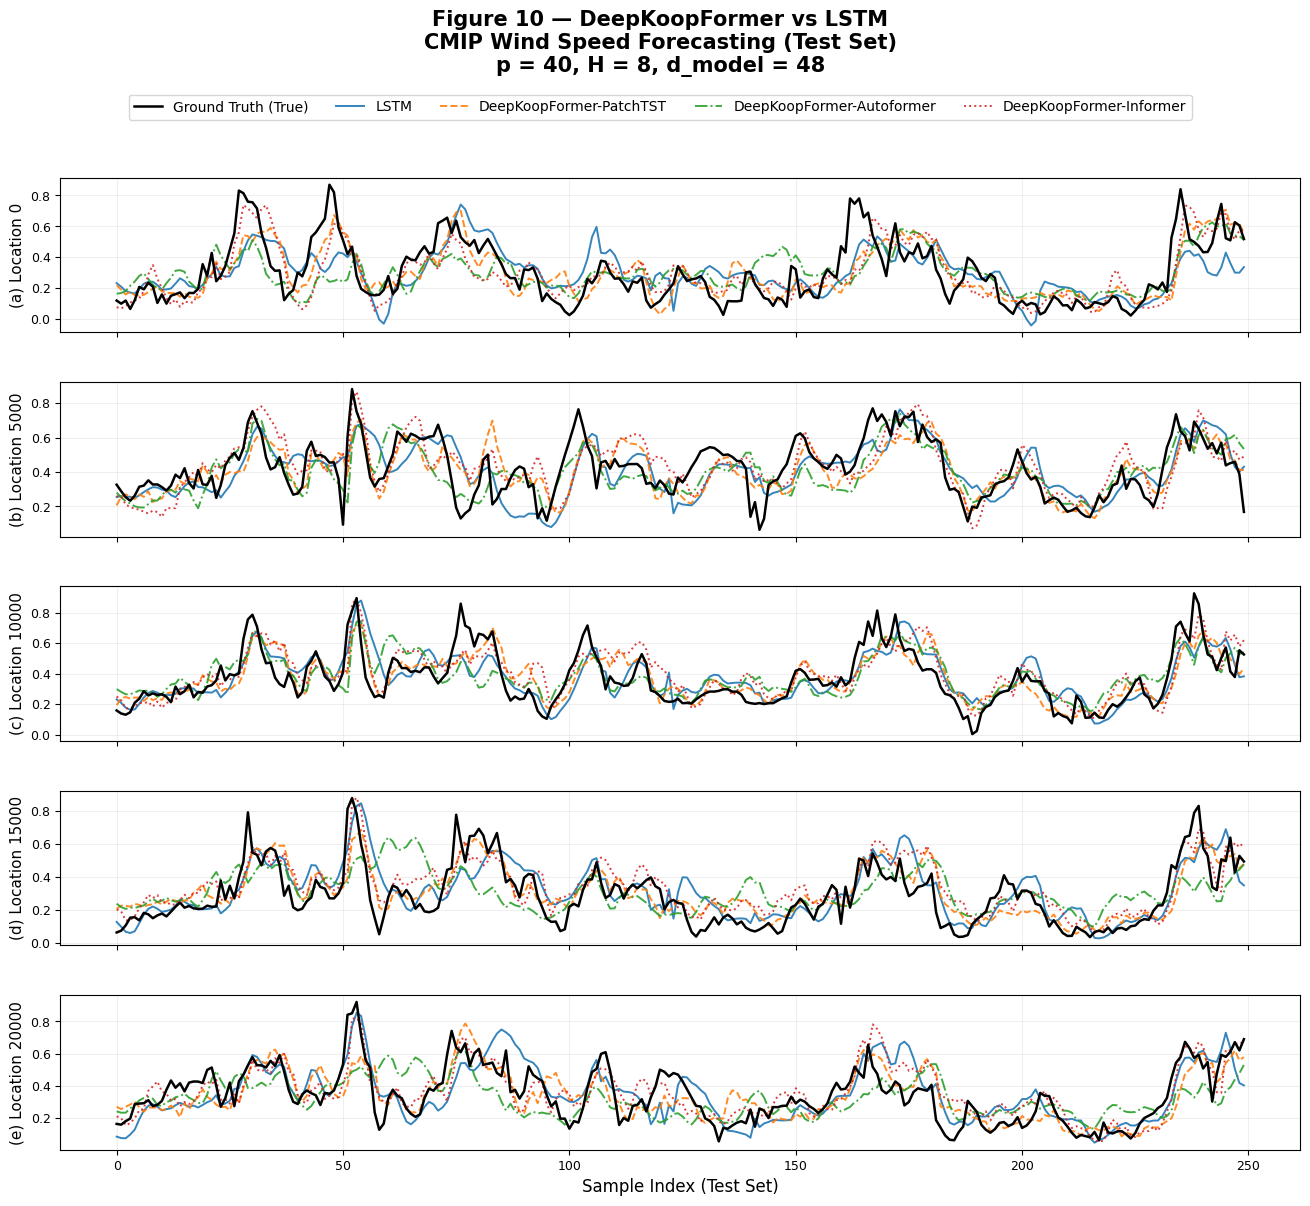

Saved: results\scenario4_train_test_e4000\figure10_test_forecasts.png


In [6]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Figure 10 — Test forecast, Scenario 4
p, h, d_model = 40, 8, 48
locations = [0, 5000, 10000, 15000, 20000]
models = ["LSTM", "PatchTST", "Autoformer", "Informer"]

styles = {
    "LSTM": {
        "label": "LSTM",
        "color": "tab:blue",
        "linestyle": "-",
    },
    "PatchTST": {
        "label": "DeepKoopFormer-PatchTST",
        "color": "tab:orange",
        "linestyle": "--",
    },
    "Autoformer": {
        "label": "DeepKoopFormer-Autoformer",
        "color": "tab:green",
        "linestyle": "-.",
    },
    "Informer": {
        "label": "DeepKoopFormer-Informer",
        "color": "tab:red",
        "linestyle": ":",
    },
}

predictions = {}
ground_truth = None

for model in models:
    path = RESULTS_DIR / f"{model.lower()}_p{p}_h{h}_d{d_model}.pt"

    ckpt = torch.load(path, map_location="cpu", weights_only=False)

    # (n_windows, 5 locations, 8 forecast steps)
    pred = ckpt["pred_test"].detach().cpu().numpy().reshape(-1, 5, h)
    truth = ckpt["truth_test"].detach().cpu().numpy().reshape(-1, 5, h)

    predictions[model] = pred[:, :, 0]

    if ground_truth is None:
        ground_truth = truth[:, :, 0]
    else:
        np.testing.assert_allclose(ground_truth, truth[:, :, 0], atol=1e-6)

# 250 consecutive test forecast windows, as in earlier forecast figures
n_show = min(250, len(ground_truth))
x = np.arange(n_show)

fig, axes = plt.subplots(
    5, 1,
    figsize=(16, 12),
    sharex=True,
    gridspec_kw={"hspace": 0.32}
)

for i, (ax, location) in enumerate(zip(axes, locations)):
    ax.plot(
        x, ground_truth[:n_show, i],
        color="black",
        linestyle="-",
        linewidth=1.8,
        label="Ground Truth (True)",
        zorder=10
    )

    for model in models:
        style = styles[model]

        ax.plot(
            x,
            predictions[model][:n_show, i],
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=1.4,
            label=style["label"],
            alpha=0.9
        )

    ax.set_ylabel(
        f"({chr(97+i)}) Location {location}",
        fontsize=11
    )
    ax.grid(alpha=0.2)
    ax.tick_params(labelsize=9)

axes[-1].set_xlabel("Sample Index (Test Set)", fontsize=12)

# Shared legend using the styles of the original forecast figures
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.955),
    ncol=5,
    fontsize=10,
    frameon=True
)

fig.suptitle(
    "Figure 10 — DeepKoopFormer vs LSTM\n"
    "CMIP Wind Speed Forecasting (Test Set)\n"
    "p = 40, H = 8, d_model = 48",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

fig.subplots_adjust(top=0.88, bottom=0.07)

output_path = RESULTS_DIR / "figure10_test_forecasts.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()
print("Saved:", output_path)